AUTCOMPLETE AND AUTOCORRECT DATA ANALYTICS

1. INSTALLING REQUIRED LIBRARIES

In [2]:
pip install nltk matplotlib pandas scikit-learn pyspellchecker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 59.6 MB/s eta 0:00:00


2. IMPORTS AND SETTINGS

In [15]:
from pathlib import Path
import re
import math
import random
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------- SETTINGS ---------------------------------------
TEXT_FILE = "cleaned_merged_fairy_tales_without_eos.txt"
RANDOM_SEED = 42
MAX_TEST_SENTENCES = 3000       # Set lower if your computer is slow
MAX_DICTIONARY_WORDS = 30000    # Limit custom autocorrect candidate search
MIN_WORD_LENGTH = 2
TOP_K = 3

random.seed(RANDOM_SEED)

3. LOADING THE DATA

In [5]:
from google.colab import files

uploaded = files.upload()

TEXT_FILE = "cleaned_merged_fairy_tales_without_eos.txt"

path = Path(TEXT_FILE)
if not path.exists():
    raise FileNotFoundError(
        f"Cannot find '{TEXT_FILE}'. Put the TXT file in the same folder as this "
        "script/notebook, or change TEXT_FILE to its full path."
    )

text = path.read_text(encoding="utf-8", errors="replace")
print("=" * 75)
print("1. DATASET INSPECTION")
print("=" * 75)
print(f"File: {path.resolve()}")
print(f"Characters: {len(text):,}")
print(f"Lines: {len(text.splitlines()):,}")
print(f"Approximate size: {path.stat().st_size / (1024 * 1024):.2f} MB")
print("\nFirst 500 characters:\n", text[:500])

Saving cleaned_merged_fairy_tales_without_eos.txt to cleaned_merged_fairy_tales_without_eos.txt
1. DATASET INSPECTION
File: /content/cleaned_merged_fairy_tales_without_eos.txt
Characters: 20,455,694
Lines: 91,760
Approximate size: 19.68 MB

First 500 characters:
 The Happy Prince.
HIGH above the city, on a tall column, stood the statue of the Happy Prince.  He was gilded all over with thin leaves of fine gold, for eyes he had two bright sapphires, and a large red ruby glowed on his sword-hilt.
He was very much admired indeed.  “He is as beautiful as a weathercock,” remarked one of the Town Councillors who wished to gain a reputation for having artistic tastes; “only not quite so useful,” he added, fearing lest people should think him unpractical, which h


4. PREPROCESSING

In [16]:
# Download NLTK stopwords if available. If unavailable, use a small fallback list.
try:
    import nltk
    from nltk.corpus import stopwords
    try:
        STOPWORDS = set(stopwords.words("english"))
    except LookupError:
        nltk.download("stopwords", quiet=True)
        STOPWORDS = set(stopwords.words("english"))
except Exception:
    STOPWORDS = {
        "a", "an", "the", "and", "or", "but", "is", "are", "was", "were",
        "be", "been", "being", "to", "of", "in", "on", "for", "with", "as",
        "at", "by", "it", "this", "that", "from", "he", "she", "they", "we",
        "you", "i", "his", "her", "their", "them", "our", "your", "not"
    }

# Sentence segmentation is deliberately simple and dependency-free.
# The corpus contains line breaks and story headings; each line is treated as a
# candidate sentence, and longer lines are additionally split at sentence endings.
raw_segments = re.split(r"(?<=[.!?])\s+|\n+", text)
raw_segments = [s.strip() for s in raw_segments if s and s.strip()]

def tokenize_words(s):
    """Lowercase and retain alphabetic words with internal apostrophes."""
    return re.findall(r"[a-z]+(?:'[a-z]+)?", s.lower())

# Tokens for language modelling: retain stopwords because they are essential
# for natural language prediction.
sentences = []
for segment in raw_segments:
    tokens = tokenize_words(segment)
    # Exclude very short fragments and headings with too little context.
    if len(tokens) >= 3:
        sentences.append(tokens)

if not sentences:
    raise ValueError("No usable sentences found. Check the TXT file encoding/content.")

# Stopword-removed tokens for demonstrating the requested preprocessing pipeline.
all_tokens = [word for sent in sentences for word in sent]
tokens_without_stopwords = [
    w for w in all_tokens if w not in STOPWORDS and len(w) >= MIN_WORD_LENGTH
]

print("\nPreprocessing summary:")
print(f"Candidate sentence segments: {len(raw_segments):,}")
print(f"Usable sentences: {len(sentences):,}")
print(f"Tokens retained for autocomplete: {len(all_tokens):,}")
print(f"Tokens after stopword removal (for frequency analysis): "
      f"{len(tokens_without_stopwords):,}")
print("Example original text:", raw_segments[0][:200])
print("Example tokens:", tokenize_words(raw_segments[0])[:20])


Preprocessing summary:
Candidate sentence segments: 211,890
Usable sentences: 198,231
Tokens retained for autocomplete: 3,812,444
Tokens after stopword removal (for frequency analysis): 1,785,336
Example original text: The Happy Prince.
Example tokens: ['the', 'happy', 'prince']


5. TOP 20 WORDS


Top 20 most frequent non-stopwords:
  Word  Frequency
  said      22650
   one      14511
little      11343
 would      10524
 could       9209
   man       7690
  like       7496
  time       7238
  came       7054
   old       6996
   see       6820
  went       6458
    go       6343
  well       6085
  good       6011
  come       5801
 great       5737
  know       5730
   day       5508
 never       5321


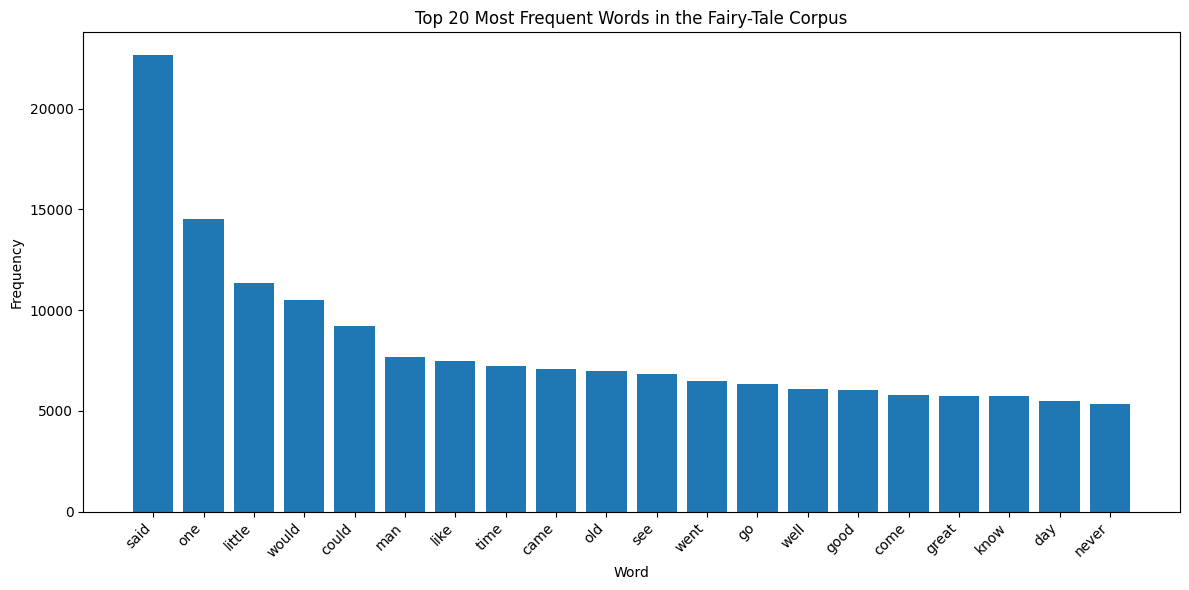

In [17]:
word_counts = Counter(tokens_without_stopwords)
top20 = word_counts.most_common(20)
freq_df = pd.DataFrame(top20, columns=["Word", "Frequency"])
print("\nTop 20 most frequent non-stopwords:")
print(freq_df.to_string(index=False))

plt.figure(figsize=(12, 6))
plt.bar(freq_df["Word"], freq_df["Frequency"])
plt.title("Top 20 Most Frequent Words in the Fairy-Tale Corpus")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("top20_frequent_words.png", dpi=150)
plt.show()

6. TRAIN-TEST SPLIT

In [18]:
# Split by sentences so the evaluation examples are not taken from the same
# sentence list used to train the n-gram models.
random.shuffle(sentences)
split_index = max(1, int(len(sentences) * 0.8))
train_sentences = sentences[:split_index]
test_sentences = sentences[split_index:]

# If the corpus is unusually small, keep at least one test sentence.
if not test_sentences:
    test_sentences = train_sentences[-1:]
    train_sentences = train_sentences[:-1]

7. N-GRAM MODELS

In [19]:
bigram_next = defaultdict(Counter)
trigram_next = defaultdict(Counter)
train_vocab = Counter()

for sent in train_sentences:
    train_vocab.update(sent)
    for i in range(1, len(sent)):
        bigram_next[sent[i - 1]][sent[i]] += 1
    for i in range(2, len(sent)):
        trigram_next[(sent[i - 2], sent[i - 1])][sent[i]] += 1

def predict_bigram(prefix, top_k=TOP_K):
    """Predict next word using the final word of a prefix."""
    words = tokenize_words(prefix)
    if not words:
        return []
    return [w for w, _ in bigram_next[words[-1]].most_common(top_k)]

def predict_trigram(prefix, top_k=TOP_K):
    """Predict next word using the final two words of a prefix; back off to bigram."""
    words = tokenize_words(prefix)
    if len(words) >= 2:
        key = (words[-2], words[-1])
        predictions = [w for w, _ in trigram_next[key].most_common(top_k)]
        if predictions:
            return predictions
    return predict_bigram(prefix, top_k)

def display_predictions(prefix):
    print(f"\nPrefix: {prefix!r}")
    print("  Bigram top 3 :", predict_bigram(prefix) or ["(no learned prediction)"])
    print("  Trigram top 3:", predict_trigram(prefix) or ["(no learned prediction)"])

print("\n" + "=" * 75)
print("5. AUTOCOMPLETE: 10 PREFIX TESTS (TOP 3 PREDICTIONS)")
print("=" * 75)

# Use real held-out sentence prefixes so tests have a known next word.
prefix_examples = []
for sent in test_sentences:
    if len(sent) >= 4:
        # Prefix of 2-5 words; the following word is the expected next word.
        prefix_len = min(random.randint(2, 5), len(sent) - 1)
        prefix = " ".join(sent[:prefix_len])
        expected = sent[prefix_len]
        if len(prefix.split()) >= 2:
            prefix_examples.append((prefix, expected))
    if len(prefix_examples) >= 10:
        break

# Fallback if test split is too small.
if len(prefix_examples) < 10:
    for sent in train_sentences:
        if len(sent) >= 4:
            prefix_examples.append((" ".join(sent[:3]), sent[3]))
        if len(prefix_examples) >= 10:
            break

prefix_examples = prefix_examples[:10]
for prefix, expected in prefix_examples:
    display_predictions(prefix)
    print("  Actual next word:", expected)


5. AUTOCOMPLETE: 10 PREFIX TESTS (TOP 3 PREDICTIONS)

Prefix: 'if the doctor knew he'
  Bigram top 3 : ['was', 'had', 'said']
  Trigram top 3: ['was', 'would', 'had']
  Actual next word: d

Prefix: 'and i you holmes'
  Bigram top 3 : ['and', 'was', 'had']
  Trigram top 3: ['answered', 'said']
  Actual next word: answered

Prefix: 'she passed along it'
  Bigram top 3 : ['was', 'is', 'and']
  Trigram top 3: ['to', 'as', 'and']
  Actual next word: the

Prefix: 'he asked'
  Bigram top 3 : ['the', 'him', 'her']
  Trigram top 3: ['the', 'for', 'her']
  Actual next word: his

Prefix: 'he often said'
  Bigram top 3 : ['the', 'to', 'he']
  Trigram top 3: ['to', 'that', 'the']
  Actual next word: when

Prefix: 'daedalous set the'
  Bigram top 3 : ['king', 'old', 'little']
  Trigram top 3: ['table', 'matter', 'trap']
  Actual next word: boy

Prefix: 'it settled deeper'
  Bigram top 3 : ['and', 'into', 'than']
  Trigram top 3: ['and', 'into', 'than']
  Actual next word: in

Prefix: 'barrow and de

6. AUTOCOMPLETE EVALUATION

In [20]:
# Evaluate only examples whose prefix contains enough context. Bigram and
# trigram are compared using top-3 prediction lists.
eval_examples = []
for sent in test_sentences[:MAX_TEST_SENTENCES]:
    if len(sent) >= 4:
        # Pick a prefix length between 2 and min(8, sentence length - 1).
        upper = min(8, len(sent) - 1)
        prefix_len = random.randint(2, upper) if upper >= 2 else 1
        prefix = " ".join(sent[:prefix_len])
        actual = sent[prefix_len]
        eval_examples.append((prefix, actual))

def autocomplete_metrics(examples, predictor, k=TOP_K):
    if not examples:
        return {"evaluated_examples": 0, "top_k_hit_rate_recall": 0.0,
                "precision_at_k": 0.0}
    hits = 0
    precision_sum = 0.0
    for prefix, actual in examples:
        preds = predictor(prefix, k)
        if actual in preds:
            hits += 1
            precision_sum += 1.0 / k  # one relevant next word among k suggestions
    return {
        "evaluated_examples": len(examples),
        "top_k_hit_rate_recall": hits / len(examples),
        "precision_at_k": precision_sum / len(examples)
    }

bigram_metrics = autocomplete_metrics(eval_examples, predict_bigram)
trigram_metrics = autocomplete_metrics(eval_examples, predict_trigram)
autocomplete_comparison = pd.DataFrame([
    {"Model": "Bigram frequency model", **bigram_metrics},
    {"Model": "Trigram frequency model (bigram backoff)", **trigram_metrics},
])
print("\nAutocomplete model comparison (held-out sentence prefixes):")
print(autocomplete_comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(
    "\nMetric notes: top_k_hit_rate_recall is the fraction of examples where the "
    "actual next word appears in the top 3. precision_at_k treats the single actual "
    "next word as relevant, so a hit contributes 1/3."
)


Autocomplete model comparison (held-out sentence prefixes):
                                   Model  evaluated_examples  top_k_hit_rate_recall  precision_at_k
                  Bigram frequency model                2900                 0.2276          0.0759
Trigram frequency model (bigram backoff)                2900                 0.2741          0.0914

Metric notes: top_k_hit_rate_recall is the fraction of examples where the actual next word appears in the top 3. precision_at_k treats the single actual next word as relevant, so a hit contributes 1/3.


9. AUTOCORRECT MODELS

In [21]:
# Create a clean-word dictionary from training text.
# Remove apostrophes for spelling candidates; retain words seen at least twice.
dictionary_counts = Counter(
    w.replace("'", "") for sent in train_sentences for w in sent
    if w.replace("'", "").isalpha() and len(w.replace("'", "")) >= MIN_WORD_LENGTH
)
dictionary_counts = Counter({
    w: c for w, c in dictionary_counts.items() if c >= 2
})
# Bound candidate set to keep the custom edit-distance method practical.
dictionary_words = [
    w for w, _ in dictionary_counts.most_common(MAX_DICTIONARY_WORDS)
]
dictionary_set = set(dictionary_words)

try:
    from spellchecker import SpellChecker
    spell = SpellChecker(distance=2)
    PYSPELLCHECKER_AVAILABLE = True
except Exception:
    spell = None
    PYSPELLCHECKER_AVAILABLE = False
    print(
        "\nWARNING: pyspellchecker is not installed. Run "
        "`pip install pyspellchecker` to enable model 1. "
        "The script will use the custom model as a fallback."
    )

def edit_distance(a, b):
    """Levenshtein edit distance using a memory-efficient dynamic-programming row."""
    if a == b:
        return 0
    if len(a) < len(b):
        a, b = b, a
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            insertion = current[j - 1] + 1
            deletion = previous[j] + 1
            substitution = previous[j - 1] + (ca != cb)
            current.append(min(insertion, deletion, substitution))
        previous = current
    return previous[-1]

# Index candidates by word length to reduce comparisons.
words_by_length = defaultdict(list)
for word in dictionary_words:
    words_by_length[len(word)].append(word)

def custom_autocorrect(word):
    """
    Custom approach:
    - If the word is already in the training dictionary, keep it.
    - Search candidates with length difference <= 2.
    - Choose the smallest edit distance; break ties using corpus frequency.
    """
    word = re.sub(r"[^a-z]", "", word.lower())
    if not word:
        return word
    if word in dictionary_set:
        return word

    candidates = []
    for length in range(max(1, len(word) - 2), len(word) + 3):
        candidates.extend(words_by_length.get(length, []))
    if not candidates:
        return word

    best_word = word
    best_distance = math.inf
    best_frequency = -1
    for candidate in candidates:
        # Skip obviously distant words.
        if abs(len(candidate) - len(word)) > 2:
            continue
        distance = edit_distance(word, candidate)
        frequency = dictionary_counts[candidate]
        if (distance < best_distance or
            (distance == best_distance and frequency > best_frequency)):
            best_word = candidate
            best_distance = distance
            best_frequency = frequency

    # Avoid making a wild correction if the closest word is too far away.
    if best_distance > 2:
        return word
    return best_word

def pyspellchecker_autocorrect(word):
    word = re.sub(r"[^a-z]", "", word.lower())
    if not word:
        return word
    if not PYSPELLCHECKER_AVAILABLE:
        return custom_autocorrect(word)
    return spell.correction(word) or word

10. 20 MIS-SPELLING TESTS

In [22]:
# Correct targets are words present in the corpus dictionary. The misspellings
# below are deliberately introduced examples, not pre-labelled dataset records.
misspelling_pairs = [
    ("prince", "prnce"),
    ("beautiful", "beautifull"),
    ("garden", "gardne"),
    ("children", "childrn"),
    ("friendship", "freindship"),
    ("happiness", "happines"),
    ("wonderful", "wonderfull"),
    ("morning", "mornng"),
    ("little", "littel"),
    ("swallow", "swalow"),
    ("winter", "wintre"),
    ("flower", "flwoer"),
    ("school", "shcool"),
    ("happy", "hapy"),
    ("golden", "goldn"),
    ("heart", "haert"),
    ("nightingale", "nightengale"),
    ("student", "studnt"),
    ("music", "musci"),
    ("story", "stroy"),
    ("world", "wrold"),
    ("love", "lvoe"),
    ("dream", "dreem"),
    ("queen", "queeen"),
    ("people", "poeple"),
]

# Prefer targets actually found in the training dictionary; otherwise retain the
# pair but clearly report if the target is outside the corpus dictionary.
test_pairs = [(correct, typo) for correct, typo in misspelling_pairs
              if correct in dictionary_set]
if len(test_pairs) < 20:
    print(
        f"\nNote: only {len(test_pairs)} of the pre-defined correct words appear "
        "in the training dictionary. Remaining examples will still be evaluated "
        "against their known intended words, but the custom method may not contain "
        "all target words."
    )
# Ensure at least 20 deliberately misspelled test examples.
test_pairs = misspelling_pairs[:]
print("\n" + "=" * 75)
print("8. AUTOCORRECT: DELIBERATELY MISSPELLED WORD TESTS")
print("=" * 75)

correct_results = []
for correct, typo in test_pairs:
    py_result = pyspellchecker_autocorrect(typo)
    custom_result = custom_autocorrect(typo)
    correct_results.append({
        "Correct word": correct,
        "Misspelling": typo,
        "PySpellChecker result": py_result,
        "Custom edit-distance result": custom_result,
        "PySpellChecker correct?": py_result == correct,
        "Custom correct?": custom_result == correct,
    })
results_df = pd.DataFrame(correct_results)
print(results_df.head(25).to_string(index=False))


8. AUTOCORRECT: DELIBERATELY MISSPELLED WORD TESTS
Correct word Misspelling PySpellChecker result Custom edit-distance result  PySpellChecker correct?  Custom correct?
      prince       prnce                 price                      prince                    False             True
   beautiful  beautifull             beautiful                   beautiful                     True             True
      garden      gardne                garden                      garden                     True             True
    children     childrn              children                    children                     True             True
  friendship  freindship            friendship                  friendship                     True             True
   happiness    happines             happiness                   happiness                     True             True
   wonderful  wonderfull             wonderful                   wonderful                     True             True
     morning

11. AUTOCORRECT METRICS


Autocorrect model comparison:
               Model  Accuracy  Precision  Recall  F1-score
      PySpellChecker    0.8800     0.8800  0.8800    0.8800
Custom edit distance    0.6000     0.6000  0.6000    0.6000


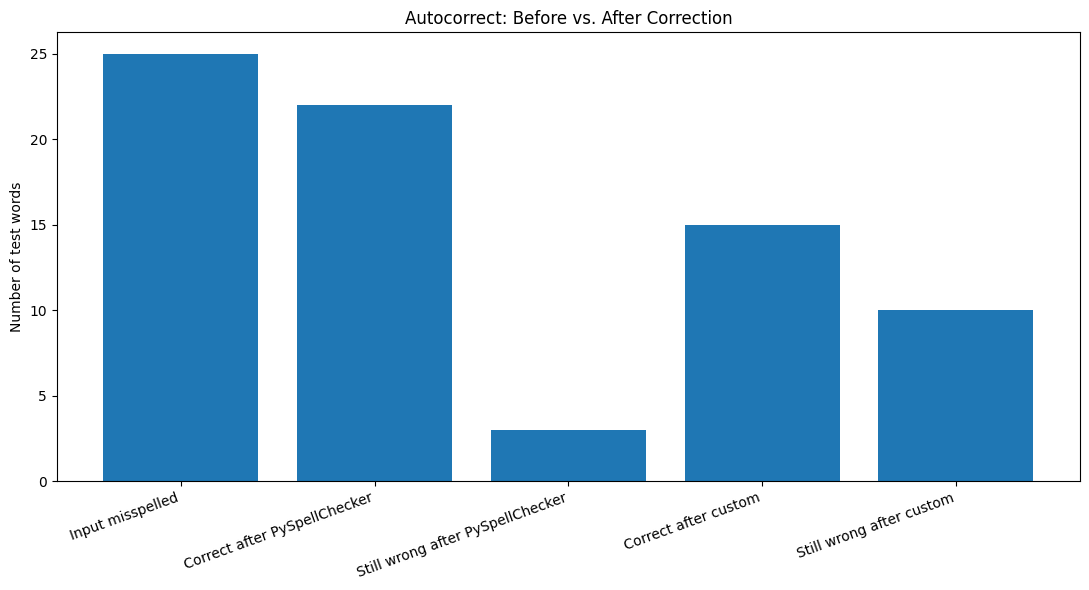

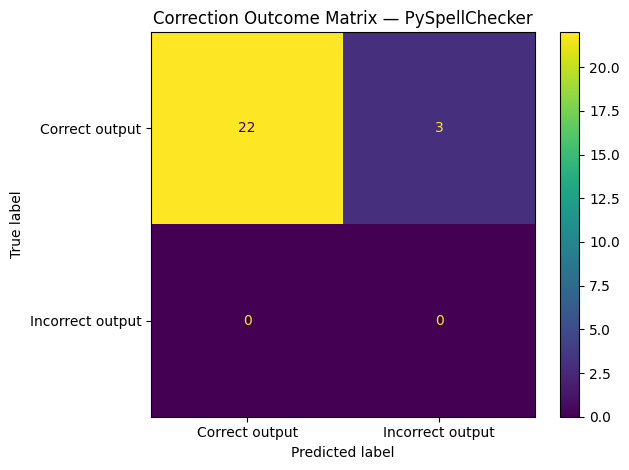

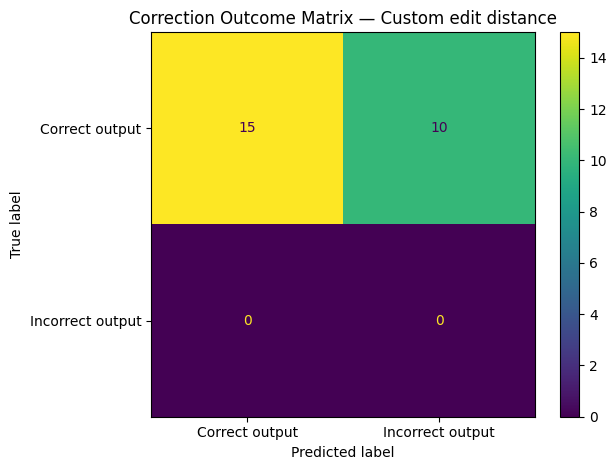

In [23]:
def spell_metrics(results_df, prediction_column):
    expected = results_df["Correct word"].str.lower()
    predicted = results_df[prediction_column].str.lower()
    exact_correct = (expected == predicted)
    accuracy = float(exact_correct.mean()) if len(results_df) else 0.0

    # Define "correction needed" as every deliberately misspelled input.
    # True positive = typo changed to its exact intended word.
    # False positive = output is not the intended word (wrong correction/no correction).
    # False negatives are failed corrections. Because every input is a typo,
    # recall equals correction accuracy for this deliberately corrupted test set.
    tp = int(exact_correct.sum())
    fp = int((~exact_correct).sum())
    fn = int((~exact_correct).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": (2 * precision * recall / (precision + recall)
                     if (precision + recall) else 0.0)
    }

spell_comparison = pd.DataFrame([
    {"Model": "PySpellChecker", **spell_metrics(results_df, "PySpellChecker result")},
    {"Model": "Custom edit distance", **spell_metrics(results_df, "Custom edit-distance result")},
])
print("\nAutocorrect model comparison:")
print(spell_comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Confusion matrix requested in the task: before vs after correction.
# For the 20+ intentionally misspelled examples, "Before" means input != target;
# "After" means corrected output == target. This is a transparent success/failure
# matrix rather than a multiclass matrix over every vocabulary word.
def correction_confusion_counts(results_df, prediction_column):
    before_wrong = results_df["Misspelling"].str.lower() != results_df["Correct word"].str.lower()
    after_correct = results_df[prediction_column].str.lower() == results_df["Correct word"].str.lower()
    return int(before_wrong.sum()), int(after_correct.sum()), int((~after_correct).sum())

before_wrong, py_after_correct, py_after_wrong = correction_confusion_counts(
    results_df, "PySpellChecker result"
)
_, custom_after_correct, custom_after_wrong = correction_confusion_counts(
    results_df, "Custom edit-distance result"
)

labels = ["Input misspelled", "Correct after PySpellChecker",
          "Still wrong after PySpellChecker", "Correct after custom",
          "Still wrong after custom"]
values = [before_wrong, py_after_correct, py_after_wrong,
          custom_after_correct, custom_after_wrong]

plt.figure(figsize=(11, 6))
plt.bar(labels, values)
plt.title("Autocorrect: Before vs. After Correction")
plt.ylabel("Number of test words")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("autocorrect_before_after.png", dpi=150)
plt.show()

# Also create a conventional 2x2 success/failure confusion matrix for each model:
# rows = actual outcome category (expected exact correction); columns = prediction
# category, interpreted as correct vs incorrect on each test example.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for model_name, col in [
    ("PySpellChecker", "PySpellChecker result"),
    ("Custom edit distance", "Custom edit-distance result"),
]:
    y_true = [1] * len(results_df)  # every intended correction is known and correct
    y_pred = [
        int(p == c) for p, c in zip(results_df[col], results_df["Correct word"])
    ]
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    # Because every test input is a typo, the all-positive ground truth creates a
    # degenerate binary confusion matrix. The before/after chart above is more
    # informative; this plot is included to satisfy the requested matrix visual.
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Correct output", "Incorrect output"]
    )
    disp.plot(values_format="d")
    plt.title(f"Correction Outcome Matrix — {model_name}")
    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(f"confusion_matrix_{safe_name}.png", dpi=150)
    plt.show()

# Save tables so results can be included in the internship report.
freq_df.to_csv("top20_frequent_words.csv", index=False)
autocomplete_comparison.to_csv("autocomplete_model_comparison.csv", index=False)
results_df.to_csv("autocorrect_test_results.csv", index=False)
spell_comparison.to_csv("autocorrect_model_comparison.csv", index=False)

12. SUMMARY AND LIMITATIONS

In [24]:
print("\n" + "=" * 75)
print("10. PROJECT SUMMARY AND LIMITATIONS")
print("=" * 75)
print("Completed outputs:")
print("- top20_frequent_words.png and top20_frequent_words.csv")
print("- 10 sample prefixes with top-3 bigram and trigram predictions")
print("- autocomplete_model_comparison.csv")
print("- autocorrect_test_results.csv")
print("- autocorrect_model_comparison.csv")
print("- autocorrect_before_after.png")
print("- confusion_matrix_pyspellchecker.png")
print("- confusion_matrix_custom_edit_distance.png")

print("""
Limitations to discuss in your notebook/report:
1. This is a frequency-based n-gram model, not a modern neural language model.
2. Predictions depend on words and word sequences observed in the training corpus.
3. A fairy-tale corpus has a limited genre and older vocabulary, so suggestions may
   not reflect modern chat, academic, or business writing.
4. Simple sentence splitting can make mistakes around abbreviations, dialogue, and
   story headings.
5. The custom autocorrect model uses a bounded dictionary and edit distance; it can
   choose the wrong word when several words are similarly spelled.
6. The deliberately misspelled test list is small and manually constructed. It is
   useful for demonstrating evaluation but is not a representative benchmark.
7. Precision/recall for autocorrect are defined here as exact correction success on
   intentionally misspelled words. A production evaluation should also include
   correctly spelled words to measure how often the system incorrectly changes them.
8. The script removes stopwords only for the frequency-analysis view. It retains
   stopwords for autocomplete because they are essential to natural word sequences.
""")

print("\nDone. Review the printed results and saved CSV/PNG files.")



10. PROJECT SUMMARY AND LIMITATIONS
Completed outputs:
- top20_frequent_words.png and top20_frequent_words.csv
- 10 sample prefixes with top-3 bigram and trigram predictions
- autocomplete_model_comparison.csv
- autocorrect_test_results.csv
- autocorrect_model_comparison.csv
- autocorrect_before_after.png
- confusion_matrix_pyspellchecker.png
- confusion_matrix_custom_edit_distance.png

Limitations to discuss in your notebook/report:
1. This is a frequency-based n-gram model, not a modern neural language model.
2. Predictions depend on words and word sequences observed in the training corpus.
3. A fairy-tale corpus has a limited genre and older vocabulary, so suggestions may
   not reflect modern chat, academic, or business writing.
4. Simple sentence splitting can make mistakes around abbreviations, dialogue, and
   story headings.
5. The custom autocorrect model uses a bounded dictionary and edit distance; it can
   choose the wrong word when several words are similarly spelled.
6. 